### 선형회귀(Linear regression)
- 입력과 출력가느이 관계를 (선형으로 놓고) 알아내는 것
    - 광고비와 매출액의 관계

- 목적 : 최적의 기울기와 절편구하기
    - 실제값과 예측값의 오차가 최소화 되게 구하는 게 목적
        -실제값과 예측ㄱ밧의 오차가 최소화 되게 구하는게 목적
        - MSE 사용
    -경사 하강법 사용

In [8]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp312-cp312-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl (70 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import torch
import matplotlib.pyplot as plt

In [23]:
x = torch.tensor([150.,100])
y = torch.tensor([150.,90])


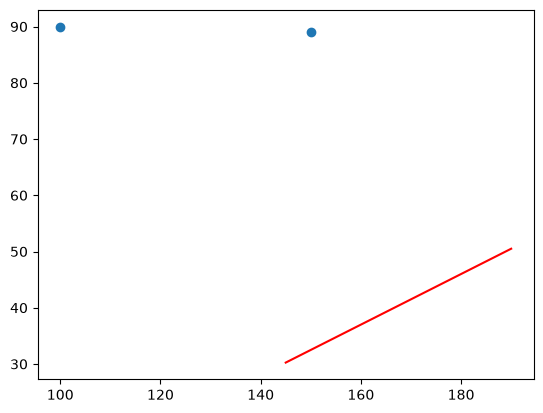

In [13]:
# 임의로 기울기와 절편 설정
a = 0.45 #기울기
b = -35 # 절편

x_plot = torch.linspace(145, 190, 100)
y_plot = a * x_plot + b

plt.figure()
plt.plot(x,y,'o')
plt.plot(x_plot, y_plot, 'r')

(0.0, 1000.0)

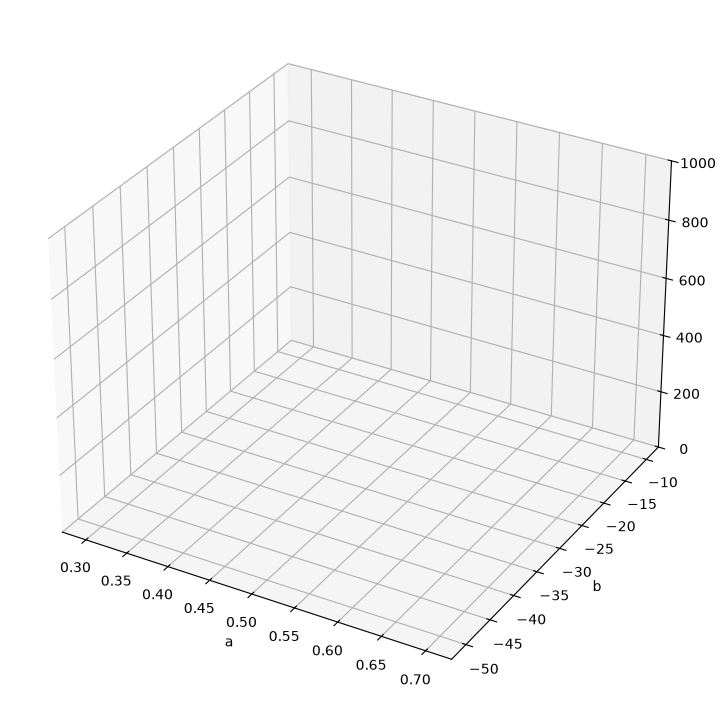

In [35]:
x = torch.tensor([150.,100])
y = torch.tensor([150.,100])

a = 0.5 + torch.linspace(-0.2, 0.2, 100) # 0.3 ~ 0.7 기울기 후보군

b = -30 + torch.linspace(-20, 20, 100) #-50 ~ -10 절편 후보군

L = torch.zeros(len(a), len(b))
N = len(x)
for i in range(len(a)):
    for j in range(len(b)):
        for n in range(N):
            L[i,j] = L[i,j] + (y[n] - (a[i]*x[n]+b[j]))**2

L = L/N #MSE

plt.figure(figsize = [10, 9])
ax = plt.axes(projection="3d")
A, B = torch.meshgrid(a, b, indexing='ij')


ax.plot_surface(A, B, L)
ax.set_xlabel('a')
ax.set_ylabel('b')
ax.set_zlim([0, 1000])

In [19]:
L

tensor([[10468.0000, 10385.7383, 10303.8047,  ...,  4008.8550,  3958.2642,
          3908.0000],
        [10366.8516, 10284.9980, 10203.4727,  ...,  3947.2937,  3897.1113,
          3847.2554],
        [10266.2344, 10184.7871, 10103.6699,  ...,  3886.2637,  3836.4893,
          3787.0415],
        ...,
        [ 3126.8391,  3084.1655,  3041.8188,  ...,   507.7104,   496.7073,
           486.0309],
        [ 3077.1545,  3034.8892,  2992.9509,  ...,   497.6135,   487.0186,
           476.7502],
        [ 3028.0000,  2986.1433,  2944.6123,  ...,   488.0470,   477.8603,
           468.0000]])

In [36]:
print(torch.min(L))
a_opt = A[L == torch.min(L)]
b_opt = B[L == torch.min(L)]
print(f'optimal a = {a_opt}') #기울기 최적
print(f'optimal b = {b_opt}') #기울기 최적
print()

tensor(2312.5000)
optimal a = tensor([0.7000])
optimal b = tensor([-10.])



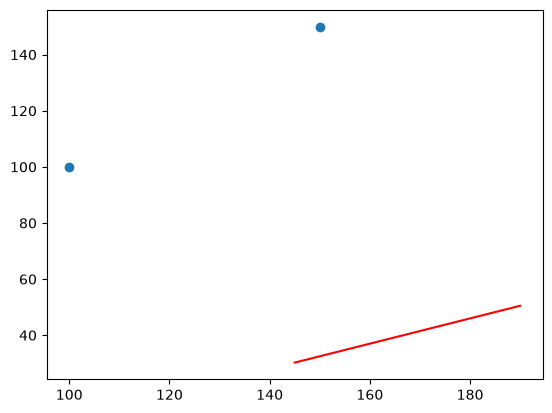

In [38]:
x_plot = torch.linspace(145, 190, 100)
t_plot = a_opt * x_plot + b_opt
plt.plot(x, y, 'o')
plt.plot(x_plot, y_plot,'r')

경사하강법

Epoch : 1, train loss : 10953.125000
Weight : 0.5299, Bias : -34.999378
Epoch : 2, train loss : 8930.011719
Weight : 0.6020, Bias : -34.998817
Epoch : 3, train loss : 7282.194336
Weight : 0.6670, Bias : -34.998310
Epoch : 4, train loss : 5940.054199
Weight : 0.7257, Bias : -34.997849
Epoch : 5, train loss : 4846.885254
Weight : 0.7787, Bias : -34.997433
Epoch : 6, train loss : 3956.505615
Weight : 0.8265, Bias : -34.997055
Epoch : 7, train loss : 3231.294189
Weight : 0.8697, Bias : -34.996716
Epoch : 8, train loss : 2640.612305
Weight : 0.9087, Bias : -34.996407
Epoch : 9, train loss : 2159.504395
Weight : 0.9438, Bias : -34.996128
Epoch : 10, train loss : 1767.644287
Weight : 0.9755, Bias : -34.995876
Epoch : 11, train loss : 1448.475586
Weight : 1.0042, Bias : -34.995647
Epoch : 12, train loss : 1188.514282
Weight : 1.0300, Bias : -34.995441
Epoch : 13, train loss : 976.776306
Weight : 1.0533, Bias : -34.995255
Epoch : 14, train loss : 804.317200
Weight : 1.0744, Bias : -34.995083
Ep

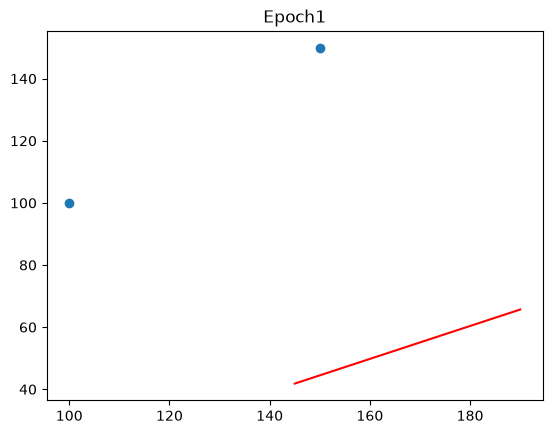

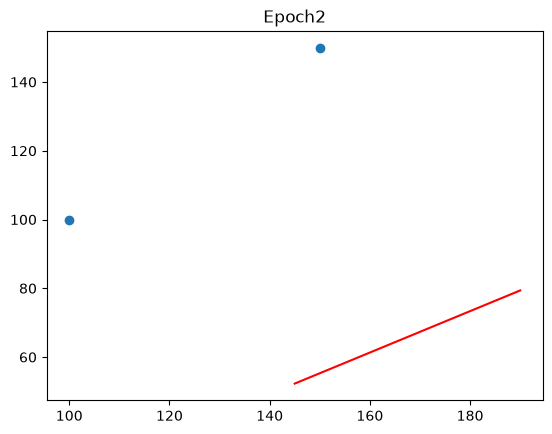

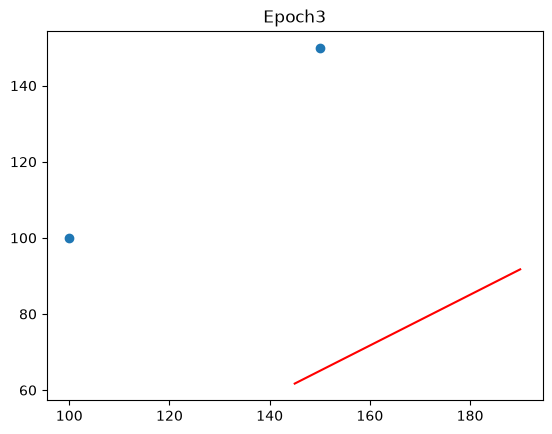

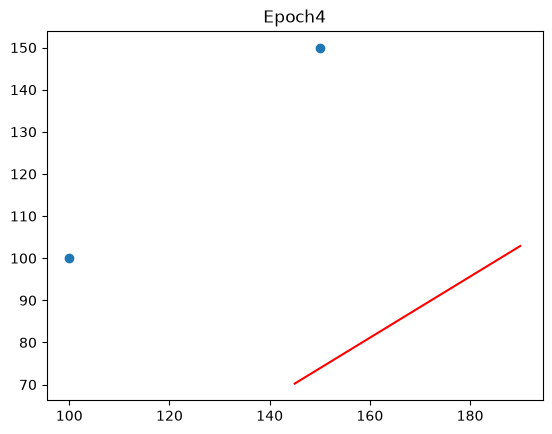

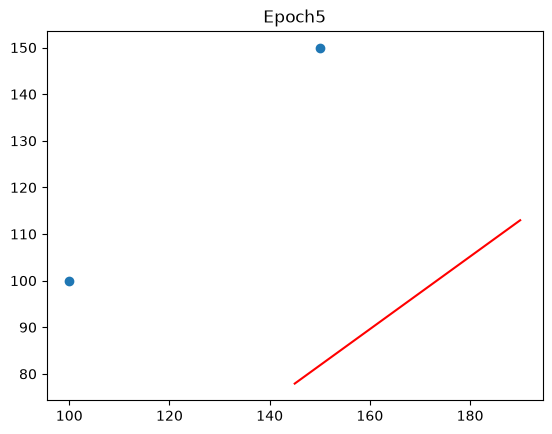

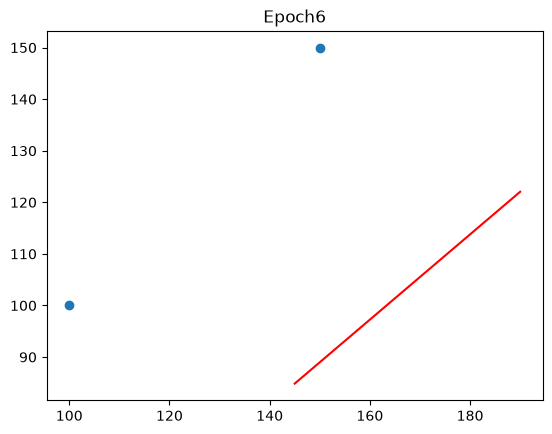

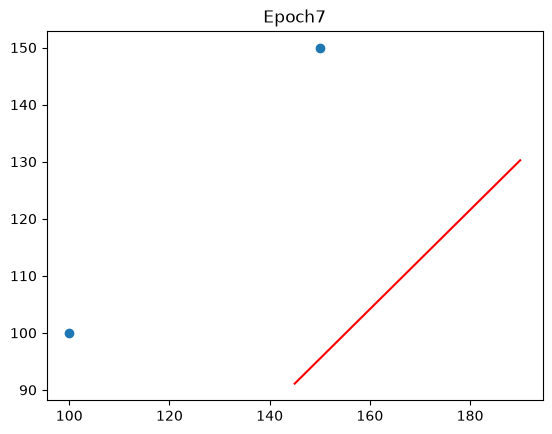

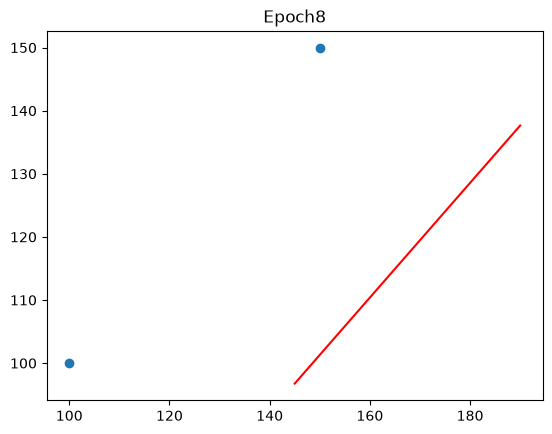

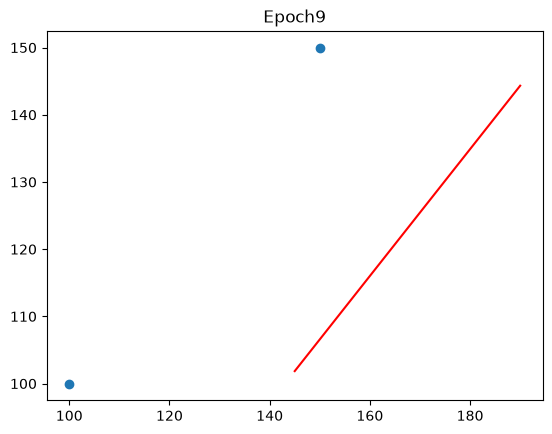

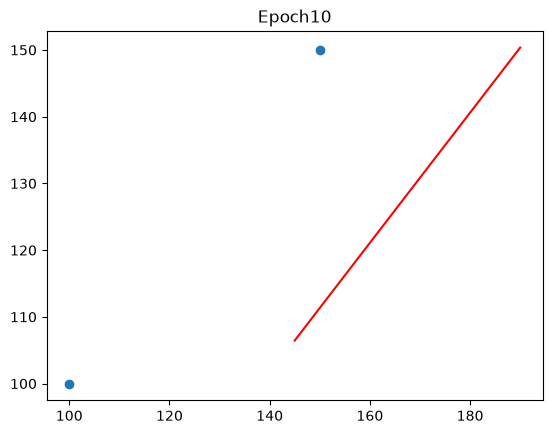

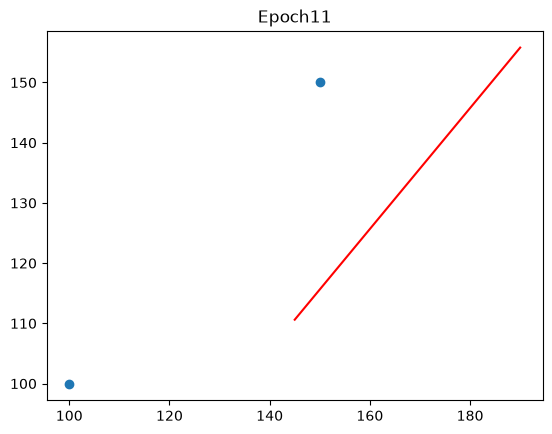

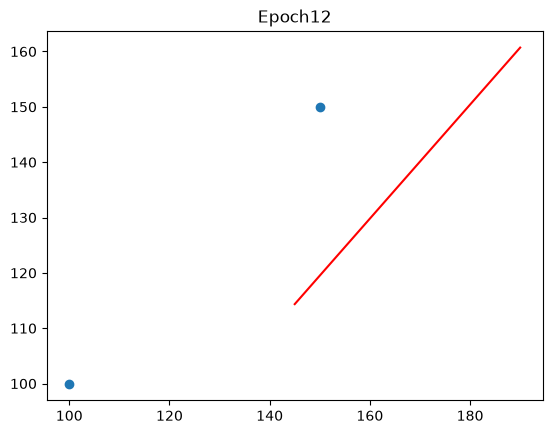

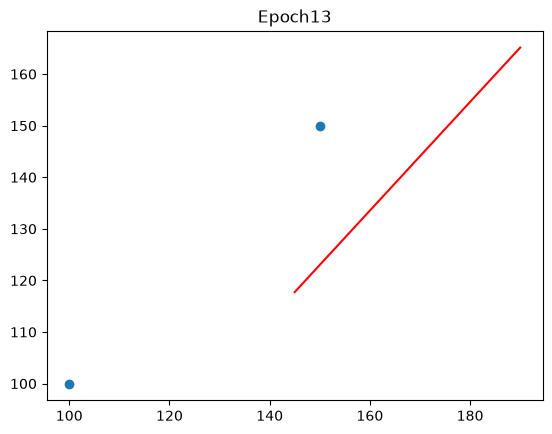

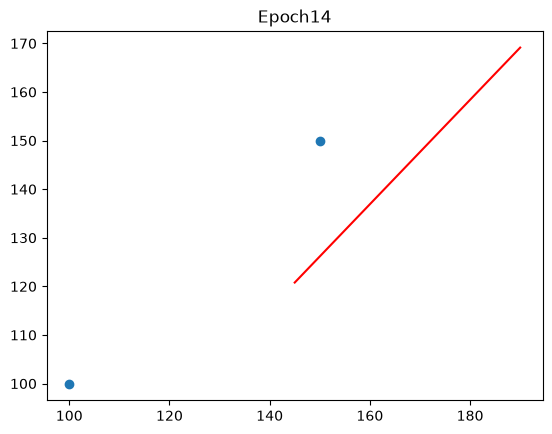

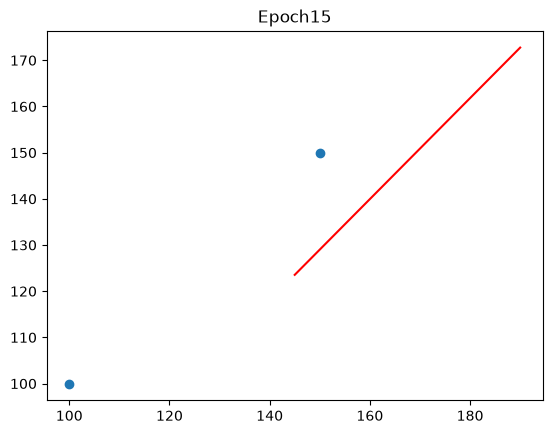

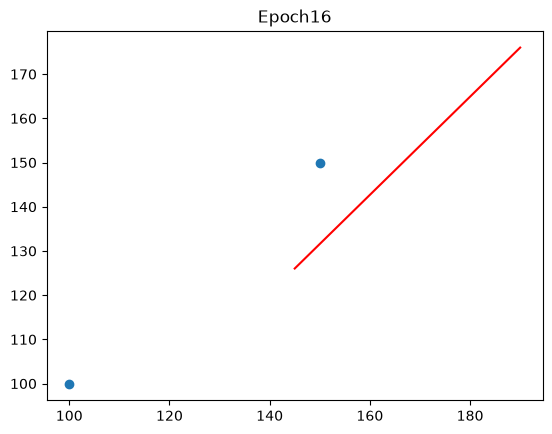

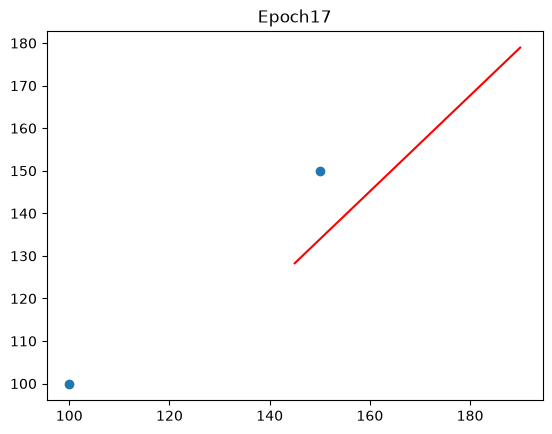

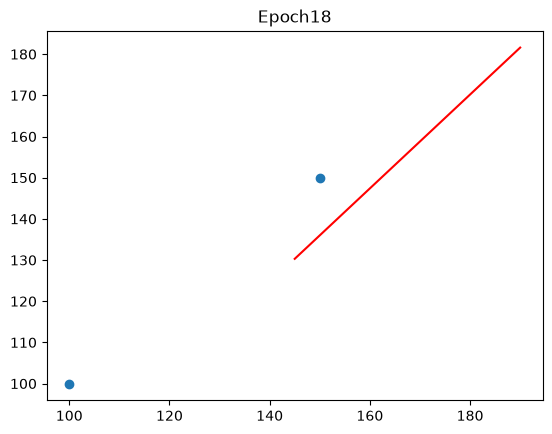

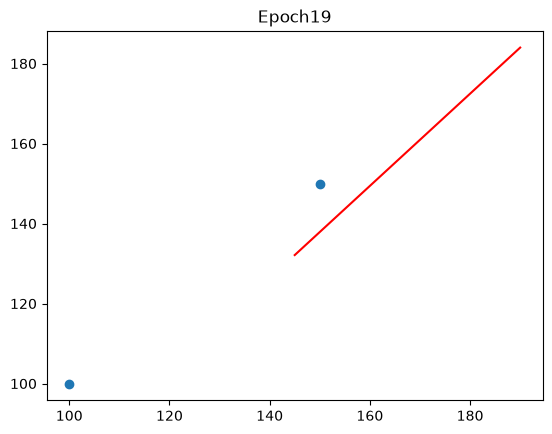

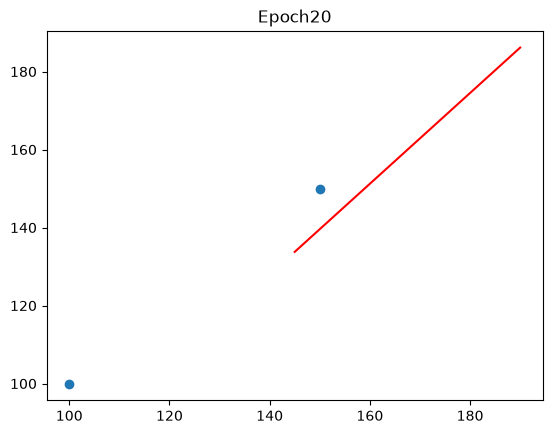

In [45]:
# 경사하강법
a = torch.tensor([0.45], requires_grad=True)
b = torch.tensor([-35.], requires_grad=True)

LR = 3e-6 # 0.000003
EPOCH = 20

loss_history = []

for ep in range(EPOCH):
    y_hat = a * x + b

    loss = 0
    for n in range(N):
        loss += (y[n] - y_hat[n])**2
    loss = loss/N

    loss.backward()

    with torch.no_grad() :
        a -= LR * a.grad
        b -= LR * b.grad

    a.grad = torch.tensor([0.])
    b.grad = torch.tensor([0.])

    loss_history += [loss.item()]

    print(f'Epoch : {ep+1}, train loss : {loss.item():4f}')
    print(f'Weight : {a.item():.4f}, Bias : {b.item():4f}')

    x_plot = torch.linspace(145, 190, 100)
    y_plot = a.detach() * x_plot + b.detach()
    plt.figure()
    plt.plot(x, y, 'o')
    plt.plot(x_plot, y_plot, 'r')
    plt.title(f'Epoch{ep+1}')